# Regression data and tiles

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
Preparing continuous-value targets and paired tiles for regression
</div>
<!-- markdownlint-enable MD033 -->

---

You know which architecture and loss function to reach for. This page prepares the data they will train on: {term}`Sentinel-2` imagery of the Beni river in the Bolivian Amazon, paired with an {term}`NDVI <Normalized Difference Vegetation Index>` raster, cut into matched {term}`tiles <Tile>` and split into a training and a validation area, ready for `geoai.train_pixel_regressor()` on the next page.

---

## 1. Motivation

Regression tiling looks like the segmentation tiling from L07, but two things deserve more care. The target side holds continuous values instead of class indices, so its value range and data type need checking. And the way you split tiles into training and validation sets decides whether your validation scores mean anything: neighbouring tiles share pixels, and a careless split lets the model be validated on pixels it has already seen.

---

## 2. Core idea

A regression dataset consists of matched pairs: an image tile and a target tile covering exactly the same location. `geoai.create_regression_tiles()` cuts both rasters into such pairs and enforces the target's valid range. We then split the pairs **by location**, holding out the southern part of the scene for validation, instead of drawing tiles at random.

The study area is a 15 × 15 km section of the Beni river, a meandering lowland river with oxbow lakes, sand bars, floodplain forest and savanna. Two Sentinel-2 scenes are available, from 2018 and 2026, each with its NDVI raster. The 2018 pair is used for training and validation; the 2026 pair is kept for testing on a year the model has never seen (pages 6 and 7).

---

## 3. Workflow

### A. Download the data

In [1]:
import json
import logging
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
logging.getLogger("rasterio").setLevel(logging.ERROR)

import geoai
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from matplotlib.patches import Rectangle
from rasterio.warp import transform as warp_transform

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
BASE_URL = "https://data.source.coop/giuz/sds320/L11/data"

files = {}
for year in [2018, 2026]:
    for kind, suffix in [("image", ""), ("ndvi", "_ndvi")]:
        name = f"beni_s2_{year}{suffix}.tif"
        files[(year, kind)] = geoai.download_file(f"{BASE_URL}/{name}", output_path=str(DATA_DIR / name))

for key, path in files.items():
    print(key, Path(path).name, f"{Path(path).stat().st_size / 1e6:.1f} MB")

(2018, 'image') beni_s2_2018.tif 23.9 MB
(2018, 'ndvi') beni_s2_2018_ndvi.tif 9.5 MB
(2026, 'image') beni_s2_2026.tif 24.2 MB
(2026, 'ndvi') beni_s2_2026_ndvi.tif 9.5 MB


The four files (about 67 MB) are stored in a local `data/` folder. `download_file()` skips files that already exist, so re-running the cell does not download them again.

### B. Inspect the data before tiling

In [2]:
with rasterio.open(files[(2018, "image")]) as src:
    print("Bands:     ", src.count, src.descriptions)
    print("Size:      ", src.width, "x", src.height, "pixels")
    print("CRS:       ", src.crs, " resolution:", src.res, "m")
    print("Data type: ", src.dtypes[0])
    image_2018 = src.read().astype("float32")
    centre_x = (src.bounds.left + src.bounds.right) / 2
    centre_y = (src.bounds.bottom + src.bounds.top) / 2
    lon, lat = warp_transform(src.crs, "EPSG:4326", [centre_x], [centre_y])
    print(f"Centre:     latitude {lat[0]:.2f}°, longitude {lon[0]:.2f}°")

with rasterio.open(files[(2018, "ndvi")]) as src:
    ndvi_2018 = src.read(1)
    print("\nTarget:    ", src.count, "band", src.descriptions, src.dtypes[0])
    print(f"NDVI range: {ndvi_2018.min():.2f} to {ndvi_2018.max():.2f}, median {np.median(ndvi_2018):.2f}")

for name, band in zip(["blue", "green", "red", "nir", "swir1", "swir2"], image_2018):
    print(f"{name:>6}: {band.min():6.0f} to {band.max():6.0f}, median {np.median(band):6.0f}")

Bands:      6 ('blue', 'green', 'red', 'nir', 'swir1', 'swir2')
Size:       1500 x 1500 pixels
CRS:        EPSG:32719  resolution: (10.0, 10.0) m
Data type:  uint16
Centre:     latitude -13.38°, longitude -67.38°

Target:     1 band ('ndvi',) float32


NDVI range: -0.72 to 0.95, median 0.80
  blue:     67 to   2264, median    257


 green:     80 to   3110, median    467
   red:     40 to   3902, median    296
   nir:     57 to   5920, median   2506
 swir1:     22 to   4811, median   1584
 swir2:      2 to   4887, median    677


Three checks matter here. The image has six bands (blue, green, red, {term}`near-infrared <Near-Infrared>` (NIR) and two {term}`shortwave-infrared <Shortwave Infrared>` bands), stored as `uint16` surface reflectance multiplied by 10,000: a value of 2,506 means 25% reflectance. The target is `float32`, as a continuous target should be. And the NDVI range lies within −1 to 1, as it must; values outside it would point to a data problem worth solving before any training.

### C. Look at both years

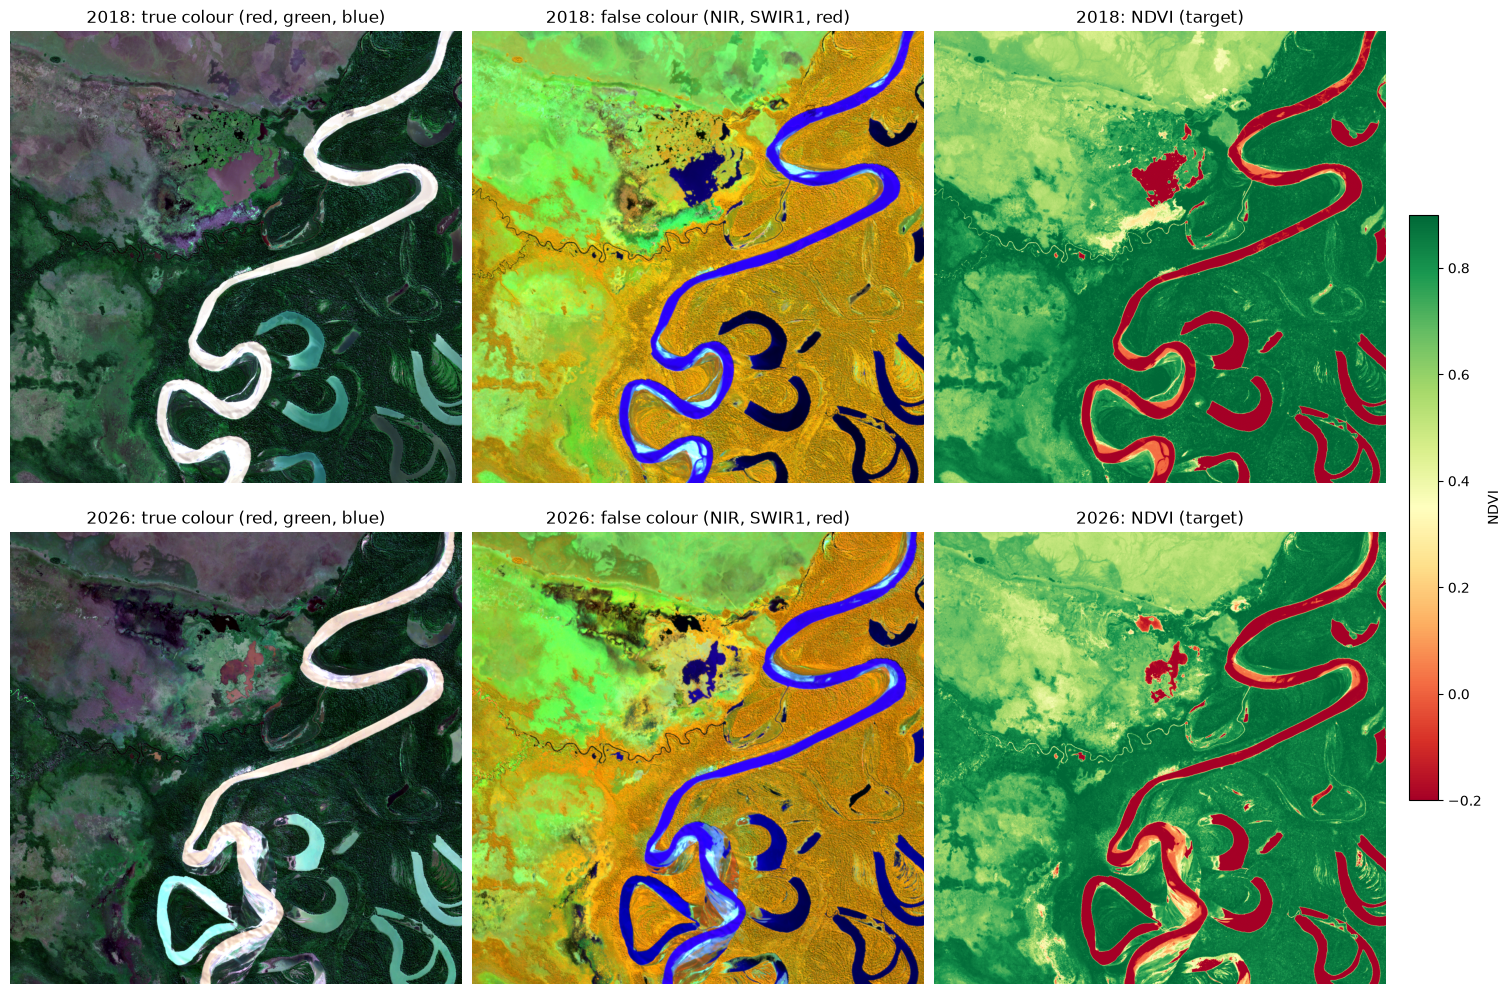

In [3]:
def stretch(bands):
    """Scale each band to 0-1 between its 2nd and 98th percentile, for display."""
    lo, hi = np.percentile(bands, (2, 98), axis=(1, 2), keepdims=True)
    return np.clip((bands - lo) / (hi - lo), 0, 1).transpose(1, 2, 0)

fig, axes = plt.subplots(2, 3, figsize=(15, 10), constrained_layout=True)
for row, year in enumerate([2018, 2026]):
    with rasterio.open(files[(year, "image")]) as src:
        img = src.read().astype("float32")
    with rasterio.open(files[(year, "ndvi")]) as src:
        ndvi = src.read(1)
    axes[row, 0].imshow(stretch(img[[2, 1, 0]]))
    axes[row, 0].set_title(f"{year}: true colour (red, green, blue)")
    axes[row, 1].imshow(stretch(img[[3, 4, 2]]))
    axes[row, 1].set_title(f"{year}: false colour (NIR, SWIR1, red)")
    im = axes[row, 2].imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.9)
    axes[row, 2].set_title(f"{year}: NDVI (target)")
    for ax in axes[row]:
        ax.set_axis_off()
fig.colorbar(im, ax=axes[:, 2], shrink=0.6, label="NDVI")
plt.show()

The sediment-laden river and the oxbow lakes have NDVI values below zero (red), bare sand bars lie just above zero (orange), floodplain forest is close to 0.9 (dark green), and the savanna in the north-west lies in between. Compare the two rows in the south-west: between 2018 and 2026 the river cut through a meander, shifted its channel and left a new oxbow lake behind. The model trained on 2018 will have to predict NDVI for this new configuration on page 6.

### D. Where the target comes from

In [4]:
red, nir = image_2018[2], image_2018[3]
ndvi_computed = (nir - red) / (nir + red)
print(f"Largest difference between the NDVI file and (NIR - red) / (NIR + red): "
      f"{np.abs(ndvi_computed - ndvi_2018).max():.1e}")

Largest difference between the NDVI file and (NIR - red) / (NIR + red): 0.0e+00


The NDVI raster is exactly (NIR − red) / (NIR + red) of the same image: the two agree to the last digit. As page 1 discussed, you would normally compute such a target, not predict it. Here it is a deliberate choice: because the correct value is known for every pixel and for both years, NDVI is an ideal target for learning the workflow. It also allows a revealing experiment on the next page: if you train **without** the NIR band, the model can no longer reproduce the formula and has to estimate NDVI from colour and spatial context, a genuine regression problem.

### E. How `geoai` scales the input

The model does not see the raw `uint16` values. Before each tile enters the network, `geoai` checks its largest value: if it is above 1.5, the tile is assumed to be reflectance × 10,000, clipped to 0–10,000 and divided by 10,000; otherwise it is assumed to be scaled to 0–1 already.

In [5]:
scaled = np.clip(image_2018, 0, 10000) / 10000
print(f"Scaled input: {scaled.min():.4f} to {scaled.max():.4f} (reflectance, 0-1)")

Scaled input: 0.0002 to 0.5920 (reflectance, 0-1)


For Sentinel-2 surface reflectance this is exactly right. For other data it may not be, and the same rule is applied during training and during prediction, so a wrong scaling is not reported as an error; the model simply learns from distorted input. Page 8 shows a case where you have to rescale the input yourself.

### F. Create paired training tiles

In [6]:
TILE_DIR = Path("regression_tiles/beni_2018")

image_paths, target_paths = geoai.create_regression_tiles(
    input_raster=files[(2018, "image")],
    target_raster=files[(2018, "ndvi")],
    output_dir=str(TILE_DIR),
    tile_size=256,
    stride=128,
    target_band=1,
    min_valid_ratio=0.9,
    target_min=-1.0,
    target_max=1.0,
)
print(f"Created {len(image_paths)} tile pairs, e.g. {Path(image_paths[0]).name}")
with rasterio.open(image_paths[0]) as src:
    print("Image tile: ", src.count, "bands,", src.width, "x", src.height, src.dtypes[0])
with rasterio.open(target_paths[0]) as src:
    print("Target tile:", src.count, "band, ", src.width, "x", src.height, src.dtypes[0])

Created 100 tile pairs, e.g. tile_000000.tif
Image tile:  6 bands, 256 x 256 uint16
Target tile: 1 band,  256 x 256 float32


`tile_size=256` with `stride=128` creates tiles that overlap by half. Along each axis the 1,500-pixel scene holds (1500 − 256) // 128 + 1 = 10 tile positions, so 10 × 10 = 100 tiles. `target_min=-1.0` and `target_max=1.0` clip target values to NDVI's valid range, and skip any tile in which more than 5% of the values lie outside it. `min_valid_ratio=0.9` skips tiles in which more than 10% of the pixels are missing (NaN). This scene has no missing values, so all 100 tiles are kept. The last tile in each row and column ends at pixel 1,152 + 256 = 1,408, so the last 92 pixels at the right and bottom edges are not covered by any tile: a tile must fit completely inside the raster.

### G. Split by location, not at random

The usual quick option is a random 80/20 split of the tile list. With overlapping tiles, that is misleading. Let us measure how many validation pixels also appear in a training tile:

In [7]:
from sklearn.model_selection import train_test_split

def tile_window(path):
    """Row and column offset of a tile in the full scene, from its georeferencing."""
    with rasterio.open(path) as tile, rasterio.open(files[(2018, "image")]) as full:
        row, col = full.index(tile.bounds.left + 1, tile.bounds.top - 1)
    return row, col

windows = [tile_window(p) for p in image_paths]

train_idx, val_idx = train_test_split(range(len(windows)), test_size=0.2, random_state=42)
in_train = np.zeros(ndvi_2018.shape, bool)
in_val = np.zeros(ndvi_2018.shape, bool)
for i in train_idx:
    r, c = windows[i]
    in_train[r:r + 256, c:c + 256] = True
for i in val_idx:
    r, c = windows[i]
    in_val[r:r + 256, c:c + 256] = True
print(f"Random split: {(in_train & in_val).sum() / in_val.sum():.0%} of the validation pixels "
      "also lie in a training tile")

Random split: 92% of the validation pixels also lie in a training tile


More than nine out of ten validation pixels were also training pixels. Validation scores from such a split mostly measure how well the model remembers what it has seen, a form of {term}`data leakage <Data Leakage>`. Even without overlap, neighbouring tiles are similar because of {term}`spatial autocorrelation <Spatial Autocorrelation>`, so randomly drawn validation tiles are easier than genuinely new areas.

A **spatial split** avoids this. We hold out the southern part of the scene: tiles that start at row 1,024 or below form the validation set, tiles that end above row 1,024 form the training set, and the row of tiles crossing the boundary is not used at all.

In [8]:
SPLIT_ROW = 1024
split = {"train": [], "val": []}
for img, tgt, (r, c) in zip(image_paths, target_paths, windows):
    if r + 256 <= SPLIT_ROW:
        split["train"].append((img, tgt))
    elif r >= SPLIT_ROW:
        split["val"].append((img, tgt))
n_dropped = len(image_paths) - len(split["train"]) - len(split["val"])
print(f"Training tiles: {len(split['train'])}, validation tiles: {len(split['val'])}, "
      f"not used (crossing the boundary): {n_dropped}")

split_file = TILE_DIR / "split.json"
split_file.write_text(json.dumps({"split_row": SPLIT_ROW, **split}, indent=1))
print("Saved to", split_file)

Training tiles: 70, validation tiles: 20, not used (crossing the boundary): 10
Saved to regression_tiles/beni_2018/split.json


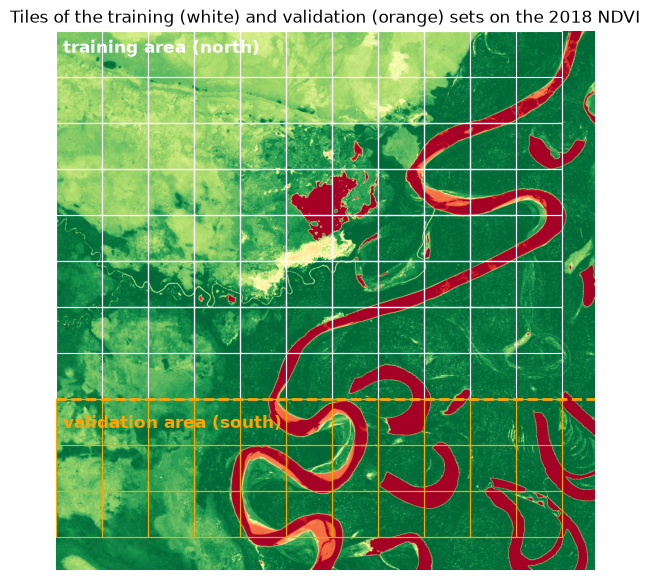

In [9]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(ndvi_2018, cmap="RdYlGn", vmin=-0.2, vmax=0.9)
for (img, _), colour in [(p, "white") for p in split["train"]] + [(p, "orange") for p in split["val"]]:
    r, c = windows[image_paths.index(img)]
    ax.add_patch(Rectangle((c, r), 256, 256, fill=False, edgecolor=colour, lw=0.8))
ax.axhline(SPLIT_ROW, color="orange", lw=2, ls="--")
ax.text(20, 60, "training area (north)", color="white", fontsize=12, weight="bold")
ax.text(20, SPLIT_ROW + 80, "validation area (south)", color="orange", fontsize=12, weight="bold")
ax.set_title("Tiles of the training (white) and validation (orange) sets on the 2018 NDVI")
ax.set_axis_off()
plt.show()

Training and validation tiles now share no pixels. The validation area also contains a good share of the difficult surfaces (river, sand bars, oxbow lakes), so it is a fair test. The price is less training data (70 instead of 80 tiles); with only 100 tiles that is noticeable, but honest validation is worth it. The split is saved to `split.json`, so the next page uses exactly the same tiles.

### H. Inspect one tile pair

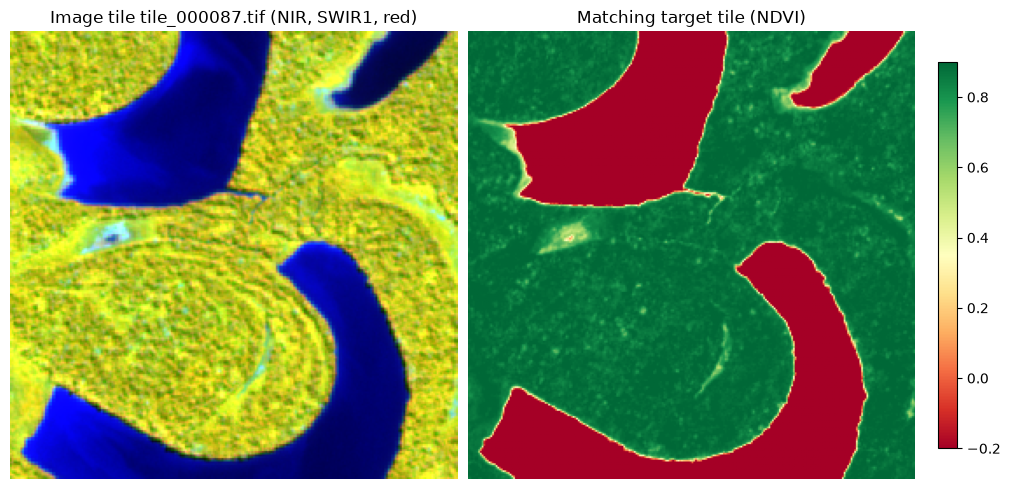

In [10]:
img_path, tgt_path = split["val"][7]
with rasterio.open(img_path) as src:
    tile = src.read().astype("float32")
with rasterio.open(tgt_path) as src:
    target = src.read(1)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)
axes[0].imshow(stretch(tile[[3, 4, 2]]))
axes[0].set_title(f"Image tile {Path(img_path).name} (NIR, SWIR1, red)")
im = axes[1].imshow(target, cmap="RdYlGn", vmin=-0.2, vmax=0.9)
axes[1].set_title("Matching target tile (NDVI)")
fig.colorbar(im, ax=axes[1], shrink=0.8)
for ax in axes:
    ax.set_axis_off()
plt.show()

Both tiles cover exactly the same 2.56 × 2.56 km. Every pixel of the target holds a continuous NDVI value, not a class index: this is what the model learns to reproduce.

---

## 4. Python reactivation

`with rasterio.open(...) as src:` is the same context-manager pattern you have used throughout this course for reading raster metadata and arrays. Two small patterns on this page are worth remembering for your own projects:

- `full.index(x, y)` converts map coordinates into a row and column of a raster, the inverse of the `transform` you know from earlier lessons. Here it locates each tile inside the full scene from the tile's own georeferencing.
- `json.dumps()` and `Path.write_text()` save a small Python structure (here the lists of training and validation tiles) as a readable text file, so a later notebook can load exactly the same split with `json.loads(Path(...).read_text())`.

---

## 5. Common pitfalls

- **Splitting overlapping tiles at random.** As measured above, most validation pixels then also occur in training tiles; the validation score becomes far too optimistic. Split by location, and leave a gap between the areas.
- **Skipping `target_min`/`target_max`.** Without them, noisy or erroneous values in the reference raster flow directly into training.
- **Not checking how the input is scaled.** `geoai` assumes either 0–1 values or reflectance × 10,000. Other data (8-bit aerial photos, radar in decibels) need rescaling first.
- **Not checking the target's value range and data type before tiling.** A quick check, as in step B, catches a data problem before it propagates into training.

---

## 6. Mini task

1. How many tiles would `create_regression_tiles()` produce from this scene with `stride=256` (no overlap)? Work it out first, then check by re-running step F with a different `output_dir`.
2. With `stride=256`, would a random split still leak validation pixels into training? Would it still be too optimistic? Explain.

:::{dropdown} Sample solution
:class: note

1. (1500 − 256) // 256 + 1 = 5 tile positions per axis, so 5 × 5 = **25 tiles**, a quarter of the 100 overlapping tiles. Overlap is the main reason the half-stride setting produces more training samples from the same scene.
2. Without overlap, no pixel would appear in both sets, so the direct leakage disappears. The validation would still be somewhat optimistic: validation tiles would be surrounded by training tiles from the same landscape, and neighbouring pixels are similar (spatial autocorrelation). A held-out *area*, as in step G, is a stricter and more realistic test of how the model performs somewhere new.
:::

---

## 7. Key takeaways

- `create_regression_tiles()` produces matched image and target tile pairs; `target_min`/`target_max` enforce the valid range and `min_valid_ratio` filters tiles with missing data.
- Check the target's data type and value range, and how `geoai` scales the input (0–1 or reflectance × 10,000), before tiling.
- Overlapping tiles multiply the number of training samples, but make random train/validation splits leak: here, more than 90% of the validation pixels were also training pixels.
- A spatial split, with a held-out area and a gap, gives validation scores you can trust.

### Further reading

- Roberts et al. (2017), ["Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure"](https://doi.org/10.1111/ecog.02881), *Ecography* 40, 913–929 — why random splits overestimate performance for spatial data, and how blocked splits help.
- [Sentinel-2 user guide](https://sentiwiki.copernicus.eu/web/s2-processing) — processing levels and the reflectance scaling of Sentinel-2 products.